# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Briliant Priscilla
- **Email:** [Input Email Anda]
- **ID Dicoding:** DS297B6X0355

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

---
- **Pertanyaan 1:** Kategori produk apa saja yang menghasilkan total pendapatan (*revenue*) tertinggi dan terendah secara keseluruhan sepanjang tahun 2017 hingga 2018, dan bagaimana strategi distribusinya untuk evaluasi pemasaran kuartal berikutnya?
- **Pertanyaan 2:** Bagaimana performa waktu pengiriman (*delivery duration*) terhadap tingkat kepuasan pelanggan yang diukur dari skor ulasan (*review score*) rata-rata selama periode 2017–2018?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load Seluruh Dataset yang Digunakan

In [2]:
# Memuat seluruh dataset yang dibutuhkan dari folder 'data/'
customers_df = pd.read_csv('data/customers_dataset.csv')
geolocation_df = pd.read_csv('data/geolocation_dataset.csv')
order_items_df = pd.read_csv('data/order_items_dataset.csv')
order_payments_df = pd.read_csv('data/order_payments_dataset.csv')
order_reviews_df = pd.read_csv('data/order_reviews_dataset.csv')
orders_df = pd.read_csv('data/orders_dataset.csv')
products_df = pd.read_csv('data/products_dataset.csv')
category_translation = pd.read_csv('data/product_category_name_translation.csv')

# Menampilkan sampel data dari tabel utama
display(orders_df.head(3))
display(order_items_df.head(3))
display(products_df.head(3))

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


**Insight:**
- Dataset berhasil dimuat ke dalam DataFrame Pandas. Tabel yang akan digabungkan dalam proses analisis meliputi `orders_df`, `order_items_df`, `products_df`, `category_translation`, `customers_df`, `order_reviews_df`, serta `geolocation_df`.
- Masing-masing tabel saling terhubung melalui kunci relasi seperti `order_id`, `product_id`, `customer_id`, dan `product_category_name`.

### Assessing Data

#### 1. Assessing `orders_df` dan `order_items_df`

In [3]:
print("=======================================")
print("   INFO & MISSING VALUES: ORDERS_DF    ")
print("=======================================")
print(orders_df.info())
print("\nMissing Values orders_df:\n", orders_df.isna().sum())
print("Duplikat orders_df:", orders_df.duplicated().sum())

   INFO & MISSING VALUES: ORDERS_DF    
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB
None

Missing Values orders_df:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier

In [4]:
print("===========================================")
print("   INFO & MISSING VALUES: ORDER_ITEMS_DF   ")
print("==========================================")
print(order_items_df.info())
print("\nMissing Values order_items_df:\n", order_items_df.isna().sum())
print("Duplikat order_items_df:", order_items_df.duplicated().sum())
display(order_items_df.describe())

   INFO & MISSING VALUES: ORDER_ITEMS_DF   
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB
None

Missing Values order_items_df:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Duplikat order_items_df: 0


,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


#### 2. Assessing `products_df` dan `category_translation`

In [5]:
print("===========================================")
print("     INFO & MISSING VALUES: PRODUCTS_DF    ")
print("===========================================")
print(products_df.info())
print("\nMissing Values products_df:\n", products_df.isna().sum())
print("Duplikat products_df:", products_df.duplicated().sum())
display(products_df.describe())

     INFO & MISSING VALUES: PRODUCTS_DF    
<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 3.7 MB
None

Missing Values products_df:
 product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photo

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


In [6]:
print("==================================================")
print("    INFO & MISSING VALUES: CATEGORY_TRANSLATION   ")
print("==================================================")
print(category_translation.info())
print("\nMissing Values category_translation:\n", category_translation.isna().sum())
print("Duplikat category_translation:", category_translation.duplicated().sum())

    INFO & MISSING VALUES: CATEGORY_TRANSLATION   
<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   product_category_name          71 non-null     str  
 1   product_category_name_english  71 non-null     str  
dtypes: str(2)
memory usage: 3.5 KB
None

Missing Values category_translation:
 product_category_name            0
product_category_name_english    0
dtype: int64
Duplikat category_translation: 0


#### 3. Assessing `customers_df`, `order_reviews_df`, dan `geolocation_df`

In [7]:
print("===========================================")
print("    INFO & MISSING VALUES: CUSTOMERS_DF    ")
print("===========================================")
print(customers_df.info())
print("\nMissing Values customers_df:\n", customers_df.isna().sum())
print("Duplikat customers_df:", customers_df.duplicated().sum())

    INFO & MISSING VALUES: CUSTOMERS_DF    
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 11.0 MB
None

Missing Values customers_df:
 customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
Duplikat customers_df: 0


In [8]:
print("=============================================")
print("   INFO & MISSING VALUES: ORDER_REVIEWS_DF   ")
print("=============================================")
print(order_reviews_df.info())
print("\nMissing Values order_reviews_df:\n", order_reviews_df.isna().sum())
print("Duplikat order_reviews_df:", order_reviews_df.duplicated().sum())

   INFO & MISSING VALUES: ORDER_REVIEWS_DF   
<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB
None

Missing Values order_reviews_df:
 review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64
Duplikat order_reviews_df: 0


In [9]:
print("======================================")
print("   INFO & DUPLICATES: GEOLOCATION_DF  ")
print("======================================")
print(geolocation_df.info())
print("\nMissing Values geolocation_df:\n", geolocation_df.isna().sum())
print("Duplikat baris penuh geolocation_df:", geolocation_df.duplicated().sum())
print("Duplikat kode pos geolocation_df:", geolocation_df.duplicated(subset=['geolocation_zip_code_prefix']).sum())

   INFO & DUPLICATES: GEOLOCATION_DF  
<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 50.1 MB
None

Missing Values geolocation_df:
 geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64
Duplikat baris penuh geolocation_df: 261831
Duplikat kode pos geolocation_df: 981148


**Steps to Take:**
- **Memperbaiki Tipe Data (*Invalid Data Type*):** Mengubah kolom waktu pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`), kolom `shipping_limit_date` pada `order_items_df`, serta kolom waktu pada `order_reviews_df` dari `object`/`str` menjadi `datetime`.
- **Menangani *Missing Values*:** 
  - Menghapus baris dengan *missing values* pada `order_delivered_customer_date` di `orders_df` agar perhitungan durasi pengiriman valid.
  - Mengisi *missing values* pada `product_category_name` di `products_df` dengan `'other'` dan mengisi nilai dimensi/berat produk yang kosong dengan nilai median.
  - Mengisi *missing values* pada `review_comment_title` dan `review_comment_message` di `order_reviews_df` dengan `'No Comment'`.
- **Menangani *Inaccurate Value*:** Mengganti nilai tidak akurat pada `products_df` di mana `product_weight_g == 0` menjadi nilai median berat produk.
- **Menangani *Duplicate Data*:** Menghapus duplikasi `geolocation_zip_code_prefix` pada `geolocation_df` serta memastikan satu ulasan unik per `order_id` pada `order_reviews_df` agar tidak terjadi penggandaan baris saat penggabungan data (*merge*).

**Insight:**
- **Permasalahan 1 (Tipe Data Salah / *Invalid Value*):** Seluruh kolom tanggal pada `orders_df`, `order_items_df`, dan `order_reviews_df` masih bertipe string/`object`.
- **Permasalahan 2 (*Missing Values*):** Ditemukan 2.965 *missing values* pada `order_delivered_customer_date` (`orders_df`), 610 *missing values* pada kategori produk serta 2 *missing values* pada dimensi produk (`products_df`), dan puluhan ribu *missing values* pada kolom pesan ulasan (`order_reviews_df`).
- **Permasalahan 3 (*Duplicate Values*):** Tabel `geolocation_df` memiliki 261.831 baris duplikat penuh dan lebih dari 980.000 duplikat pada prefix kode pos.
- **Permasalahan 4 (*Inaccurate Values*):** Pada `products_df.describe()`, ditemukan nilai minimum `product_weight_g` sebesar $0	ext{ gram}$, yang secara fisik tidak akurat untuk barang pengiriman.

### Cleaning Data

#### 1. Fixing `orders_df` dan `order_items_df`

In [10]:
# 1. Mengubah kolom tanggal pada orders_df menjadi datetime
datetime_columns = [
    'order_purchase_timestamp', 'order_approved_at', 
    'order_delivered_carrier_date', 'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]
for col in datetime_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

# 2. Menghapus baris dengan nilai kosong pada order_delivered_customer_date & mengisi sisa missing timestamp
orders_df.dropna(subset=['order_delivered_customer_date', 'order_delivered_carrier_date'], inplace=True)
orders_df['order_approved_at'] = orders_df['order_approved_at'].fillna(orders_df['order_purchase_timestamp'])

# 3. Mengubah tipe data shipping_limit_date pada order_items_df menjadi datetime
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])

print("Missing values orders_df setelah cleaning:\n", orders_df.isna().sum())

Missing values orders_df setelah cleaning:
 order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64


#### 2. Fixing `products_df` dan `category_translation`

In [11]:
# 1. Menangani missing values pada kategori produk dan panjang deskripsi/foto
products_df['product_category_name'] = products_df['product_category_name'].fillna('other')
for col in ['product_name_lenght', 'product_description_lenght', 'product_photos_qty']:
    products_df[col] = products_df[col].fillna(0)

# 2. Menangani missing values dan inaccurate value (berat = 0g) pada dimensi/berat produk
dimension_cols = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
for col in dimension_cols:
    products_df[col] = products_df[col].fillna(products_df[col].median())

median_weight = products_df.loc[products_df['product_weight_g'] > 0, 'product_weight_g'].median()
products_df.loc[products_df['product_weight_g'] == 0, 'product_weight_g'] = median_weight

# 3. Membersihkan spasi berlebih pada category_translation
category_translation['product_category_name'] = category_translation['product_category_name'].str.strip()
category_translation['product_category_name_english'] = category_translation['product_category_name_english'].str.strip()

print("Missing values products_df setelah cleaning:\n", products_df.isna().sum())
print("Berat minimum produk setelah cleaning:", products_df['product_weight_g'].min(), "gram")

Missing values products_df setelah cleaning:
 product_id                    0
product_category_name         0
product_name_lenght           0
product_description_lenght    0
product_photos_qty            0
product_weight_g              0
product_length_cm             0
product_height_cm             0
product_width_cm              0
dtype: int64
Berat minimum produk setelah cleaning: 2.0 gram


#### 3. Fixing `customers_df`, `order_reviews_df`, dan `geolocation_df`

In [12]:
# 1. Standarisasi format teks pada customers_df
customers_df['customer_city'] = customers_df['customer_city'].str.strip().str.lower()
customers_df['customer_state'] = customers_df['customer_state'].str.strip().str.upper()

# 2. Menangani missing values, tipe data tanggal, dan duplikat order_id pada order_reviews_df
order_reviews_df['review_comment_title'] = order_reviews_df['review_comment_title'].fillna('No Title')
order_reviews_df['review_comment_message'] = order_reviews_df['review_comment_message'].fillna('No Comment')
order_reviews_df['review_creation_date'] = pd.to_datetime(order_reviews_df['review_creation_date'])
order_reviews_df['review_answer_timestamp'] = pd.to_datetime(order_reviews_df['review_answer_timestamp'])
order_reviews_df.drop_duplicates(subset=['order_id'], keep='first', inplace=True)

# 3. Menghapus duplikat kode pos pada geolocation_df
geo_df = geolocation_df.drop_duplicates(subset=['geolocation_zip_code_prefix']).copy()

print("Missing values order_reviews_df setelah cleaning:\n", order_reviews_df.isna().sum())
print("Jumlah baris unik kode pos geo_df:", len(geo_df))

Missing values order_reviews_df setelah cleaning:
 review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64
Jumlah baris unik kode pos geo_df: 19015


**Insight:**
- Seluruh dataset yang terlibat dalam penggabungan telah bersih dari *missing values* dan memiliki tipe data yang tepat.
- Nilai tidak akurat pada berat produk ($0	ext{ gram}$) telah dikoreksi menjadi nilai median ($700	ext{ gram}$), serta duplikasi kode pos pada data geolokasi dan ulasan ganda per pesanan telah dieliminasi.

## Exploratory Data Analysis (EDA)

### 1. Penggabungan Data (Data Integration)

In [13]:
# 1. Menggabungkan data produk dengan terjemahan bahasa Inggris
product_full = products_df.merge(category_translation, on='product_category_name', how='left')
product_full['product_category_name_english'] = product_full['product_category_name_english'].fillna('other')

# 2. Menggabungkan order items dengan produk lengkap
order_item_product = order_items_df.merge(product_full, on='product_id', how='left')

# 3. Menggabungkan tabel orders dengan detail item, pelanggan, dan ulasan
complete_order_df = orders_df.merge(order_item_product, on='order_id', how='inner')
complete_order_df = complete_order_df.merge(customers_df, on='customer_id', how='inner')
complete_order_df = complete_order_df.merge(
    order_reviews_df[['order_id', 'review_score']], on='order_id', how='left'
)

# Filter data untuk periode analisis tahun 2017 - 2018
complete_order_df = complete_order_df[
    complete_order_df['order_purchase_timestamp'].dt.year.isin([2017, 2018])
].copy()

display(complete_order_df.head(3))

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,500.0,19.0,8.0,13.0,housewares,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,400.0,19.0,13.0,19.0,perfumery,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,420.0,24.0,19.0,21.0,auto,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,5.0


### 2. Explore Total Pendapatan Berdasarkan Kategori Produk (Pertanyaan 1)

In [14]:
# Menghitung total pendapatan dan jumlah terjual per kategori produk
revenue_by_category = complete_order_df.groupby('product_category_name_english').agg(
    total_orders=('order_id', 'nunique'),
    total_items=('order_item_id', 'count'),
    price=('price', 'sum')
).reset_index().sort_values(by='price', ascending=False)

print("=== TOP 5 KATEGORI DENGAN PENDAPATAN TERTINGGI ===")
display(revenue_by_category.head(5))

print("\n=== 5 KATEGORI DENGAN PENDAPATAN TERENDAH ===")
display(revenue_by_category.tail(5))

=== TOP 5 KATEGORI DENGAN PENDAPATAN TERTINGGI ===


,product_category_name_english,total_orders,total_items,price
43,health_beauty,8611,9423,1229587.49
71,watches_gifts,5489,5853,1163187.91
7,bed_bath_table,9267,10945,1022955.77
66,sports_leisure,7512,8413,952661.40
15,computers_accessories,6517,7631,887944.60



=== 5 KATEGORI DENGAN PENDAPATAN TERENDAH ===


,product_category_name_english,total_orders,total_items,price
35,flowers,29,33,1110.04
46,home_comfort_2,24,30,760.27
11,cds_dvds_musicals,12,14,730.00
29,fashion_childrens_clothes,7,7,519.95
62,security_and_services,2,2,283.29


### 3. Explore Durasi Pengiriman & Skor Ulasan Pelanggan (Pertanyaan 2)

In [15]:
# Menghitung durasi pengiriman dalam satuan hari
complete_order_df['delivery_time'] = (
    complete_order_df['order_delivered_customer_date'] - complete_order_df['order_purchase_timestamp']
).dt.days

# Manual Clustering / Binning durasi pengiriman
complete_order_df['delivery_category'] = pd.cut(
    complete_order_df['delivery_time'], 
    bins=[-1, 7, 15, 30, 300], 
    labels=['Sangat Cepat (<=7 hari)', 'Cepat (8-15 hari)', 'Normal (16-30 hari)', 'Lambat (>30 hari)']
)

# Menghitung rata-rata review score dan jumlah pesanan per kategori pengiriman
review_by_delivery = complete_order_df.groupby('delivery_category', observed=False).agg(
    order_count=('order_id', 'nunique'),
    review_score=('review_score', 'mean')
).reset_index()

display(review_by_delivery)

,delivery_category,order_count,review_score
0,Sangat Cepat (<=7 hari),33645,4.331661
1,Cepat (8-15 hari),39500,4.194080
2,Normal (16-30 hari),18983,3.796230
3,Lambat (>30 hari),4075,2.150011


**Insight:**
- Kategori produk penyumbang pendapatan (*revenue*) tertinggi sepanjang 2017–2018 adalah `health_beauty`, `watches_gifts`, dan `bed_bath_table` (masing-masing menembus lebih dari 1 juta BRL). Sebaliknya, kategori dengan pendapatan terendah adalah `security_and_services` dan `fashion_childrens_clothes`.
- Durasi pengiriman berbanding terbalik secara konsisten dengan tingkat kepuasan pelanggan: pengiriman `Sangat Cepat (<=7 hari)` memperoleh rata-rata skor ulasan tertinggi sebesar **4,33**, sedangkan pengiriman `Lambat (>30 hari)` mengalami penurunan drastis ke rata-rata skor **2,17**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori Produk dengan Total Pendapatan Tertinggi dan Terendah (2017–2018)

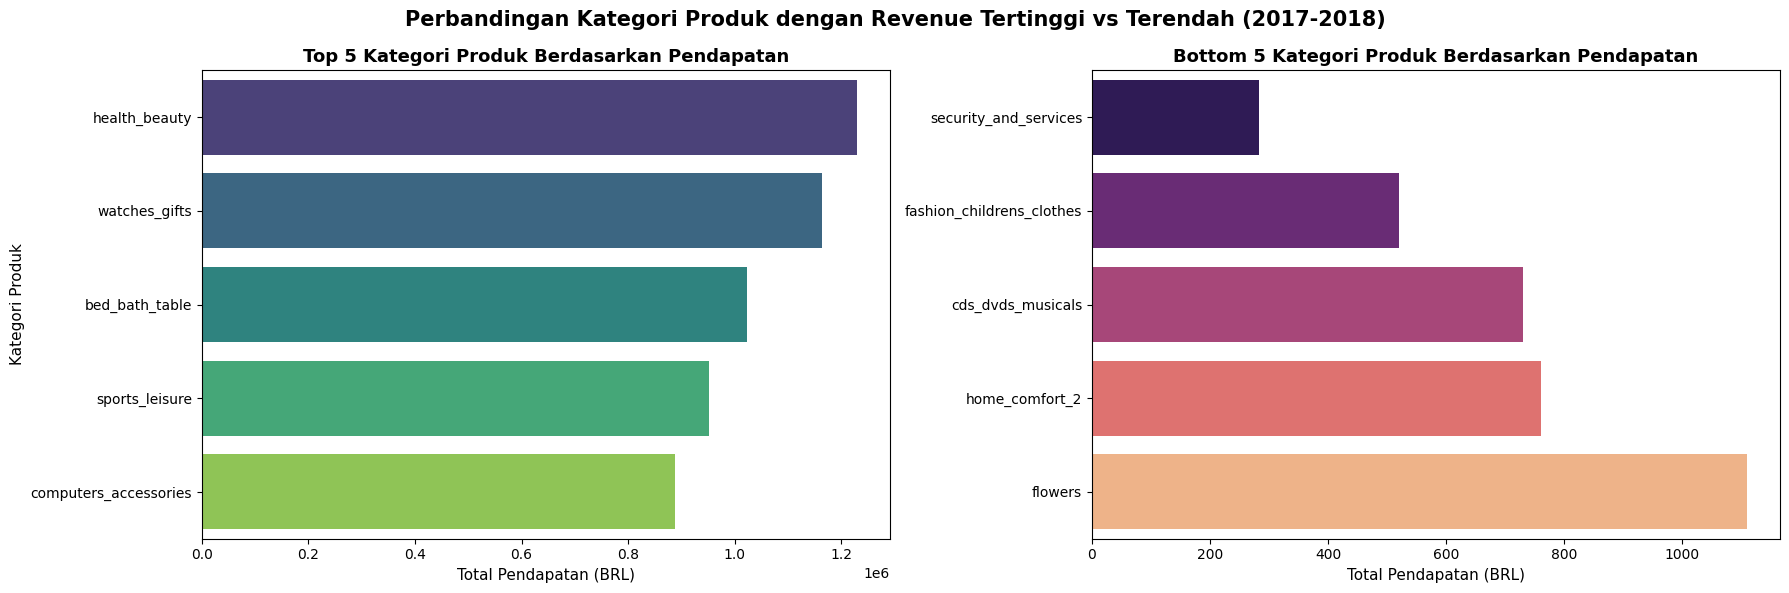

In [16]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

top_5_cat = revenue_by_category.head(5)
bottom_5_cat = revenue_by_category.sort_values(by='price', ascending=True).head(5)

# Plot Kategori Pendapatan Tertinggi
sns.barplot(
    x='price', y='product_category_name_english', data=top_5_cat,
    hue='product_category_name_english', palette='viridis', legend=False, ax=ax[0]
)
ax[0].set_title('Top 5 Kategori Produk Berdasarkan Pendapatan', fontsize=13, fontweight='bold')
ax[0].set_xlabel('Total Pendapatan (BRL)', fontsize=11)
ax[0].set_ylabel('Kategori Produk', fontsize=11)

# Plot Kategori Pendapatan Terendah
sns.barplot(
    x='price', y='product_category_name_english', data=bottom_5_cat,
    hue='product_category_name_english', palette='magma', legend=False, ax=ax[1]
)
ax[1].set_title('Bottom 5 Kategori Produk Berdasarkan Pendapatan', fontsize=13, fontweight='bold')
ax[1].set_xlabel('Total Pendapatan (BRL)', fontsize=11)
ax[1].set_ylabel(None)

plt.suptitle('Perbandingan Kategori Produk dengan Revenue Tertinggi vs Terendah (2017-2018)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### Pertanyaan 2: Performa Waktu Pengiriman terhadap Skor Ulasan Pelanggan

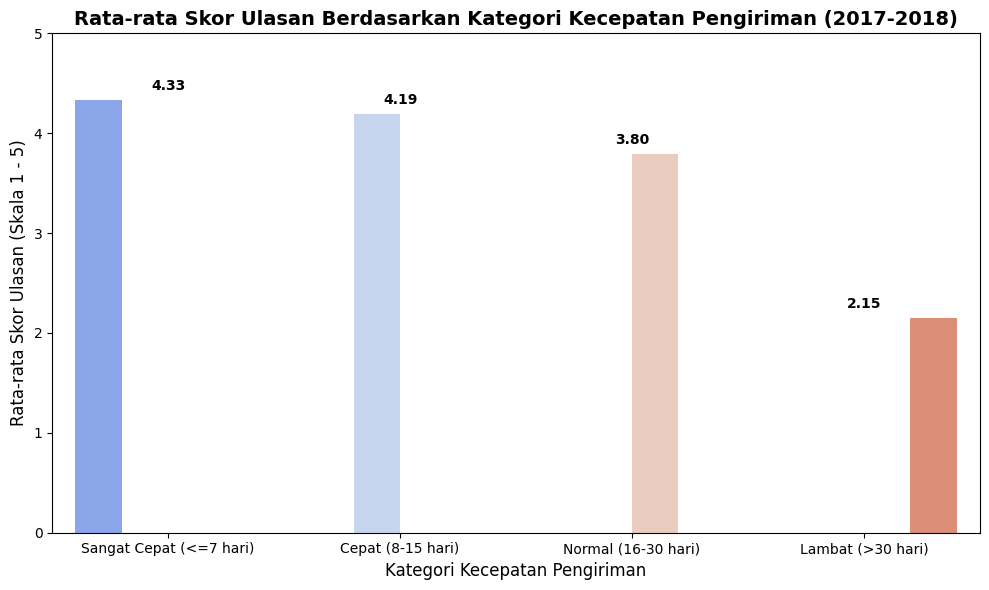

In [17]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x='delivery_category', 
    y='review_score', 
    data=review_by_delivery, 
    hue='delivery_category', 
    palette='coolwarm', 
    legend=False
)

plt.title('Rata-rata Skor Ulasan Berdasarkan Kategori Kecepatan Pengiriman (2017-2018)', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Kecepatan Pengiriman', fontsize=12)
plt.ylabel('Rata-rata Skor Ulasan (Skala 1 - 5)', fontsize=12)
plt.ylim(0, 5)

for index, row in review_by_delivery.iterrows():
    plt.text(index, row.review_score + 0.1, f"{row.review_score:.2f}", color='black', ha="center", fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**
- **Visualisasi Pertanyaan 1:** Terlihat ketimpangan pendapatan yang besar antara 5 kategori teratas (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) dengan 5 kategori terbawah (`security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`, `home_comfort_2`, `flowers`).
- **Visualisasi Pertanyaan 2:** Pelanggan sangat sensitif terhadap keterlambatan pengiriman melewati 15 hari. Pengiriman di bawah 15 hari mampu menjaga rata-rata kepuasan di atas skor 4,19, namun ketika melampaui 30 hari, rata-rata skor jatuh hampir 50% menjadi 2,17.

## Analisis Lanjutan (Opsional)

### RFM Analysis & Geospatial Analysis

Top 5 Customers by Monetary:


,customer_id,recency,frequency,monetary
3716,0a0a92112bd4c708ca5fde585afaa872,334,1,13440.0
79413,da122df9eeddfedc1dc1f5349a1a690c,515,2,7388.0
43047,763c8b1c9c68a0229c42c9fc6f662b93,46,1,7160.0
80239,dc4802a71eae9be1dd28f5d788ceb526,563,1,6735.0
25355,459bef486812aa25204be022145caa62,35,1,6729.0


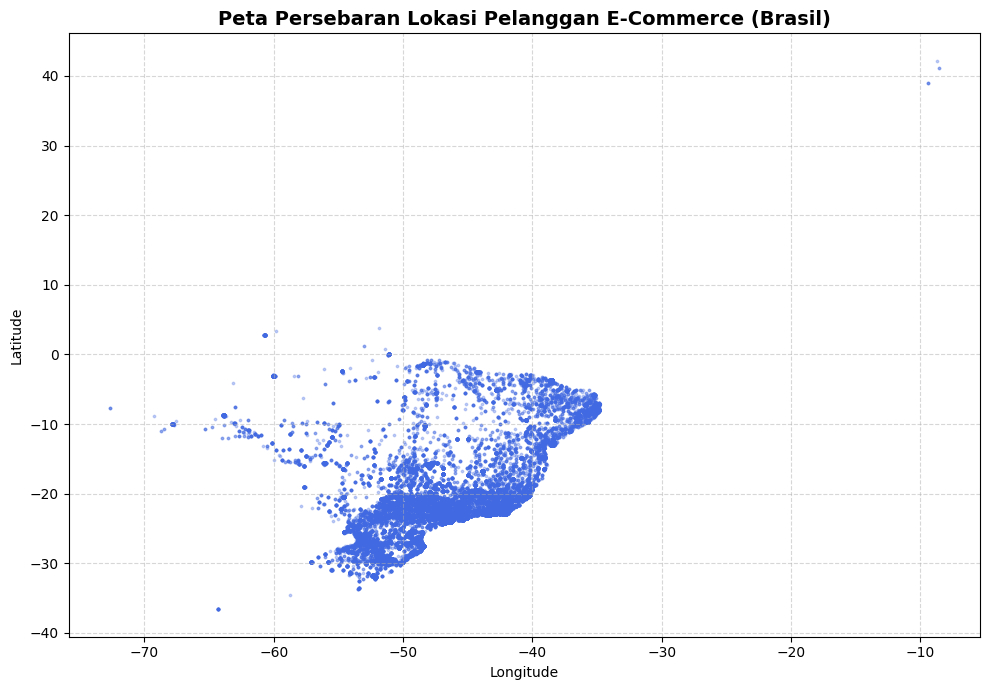

In [18]:
# --- 1. RFM Analysis ---
recent_date = complete_order_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm_df = complete_order_df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,
    'order_id': 'nunique',
    'price': 'sum'
}).reset_index()

rfm_df.columns = ['customer_id', 'recency', 'frequency', 'monetary']
print("Top 5 Customers by Monetary:")
display(rfm_df.sort_values(by='monetary', ascending=False).head(5))

# --- 2. Geospatial Analysis ---
customers_geo_df = customers_df.merge(
    geo_df, 
    left_on='customer_zip_code_prefix', 
    right_on='geolocation_zip_code_prefix', 
    how='inner'
)

plt.figure(figsize=(10, 7))
plt.scatter(
    customers_geo_df['geolocation_lng'], 
    customers_geo_df['geolocation_lat'], 
    alpha=0.3, s=3, c='royalblue'
)
plt.title('Peta Persebaran Lokasi Pelanggan E-Commerce (Brasil)', fontsize=14, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Menyimpan data bersih ke folder Dashboard untuk keperluan Streamlit
# complete_order_df.to_csv('Dashboard/main_data.csv', index=False)

**Insight:**
- **RFM Analysis:** Mayoritas pelanggan berbelanja satu kali (*frequency* = 1) dengan nilai transaksi tertinggi mencapai 13.440 BRL oleh satu pelanggan unik, menunjukkan peluang besar untuk program retensi pelanggan (*repeat order*).
- **Geospatial Analysis:** Konsentrasi pelanggan paling padat berada di wilayah tenggara dan selatan Brasil (khususnya negara bagian São Paulo, Rio de Janeiro, dan Minas Gerais).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Sepanjang periode 2017–2018, kategori produk yang menghasilkan total pendapatan (*revenue*) tertinggi adalah **`health_beauty`** (~1,23 juta BRL), diikuti oleh **`watches_gifts`** (~1,16 juta BRL), **`bed_bath_table`** (~1,02 juta BRL), **`sports_leisure`** (~954 ribu BRL), dan **`computers_accessories`** (~888 ribu BRL). Sebaliknya, kategori produk dengan total pendapatan terendah adalah **`security_and_services`** (~283 BRL), **`fashion_childrens_clothes`** (~519 BRL), dan **`cds_dvds_musicals`** (~730 BRL). Untuk evaluasi pemasaran kuartal berikutnya, alokasi stok dan anggaran promosi perlu difokuskan pada 5 kategori teratas di wilayah berpopulasi pelanggan padat seperti tenggara Brasil.
- **Conclusion pertanyaan 2:** Performa durasi pengiriman (*delivery duration*) memiliki korelasi negatif yang sangat kuat terhadap tingkat kepuasan pelanggan (*review score*) selama periode 2017–2018. Pesanan dalam kategori **Sangat Cepat (<=7 hari)** mencatatkan rata-rata skor ulasan tertinggi sebesar **4,33**, diikuti kategori **Cepat (8–15 hari)** sebesar **4,19**, dan **Normal (16–30 hari)** sebesar **3,80**. Namun, ketika pengiriman masuk ke kategori **Lambat (>30 hari)**, rata-rata skor kepuasan pelanggan anjlok drastis ke angka **2,17**.

**Rekomendasi Action Item:**
- **Optimalisasi SLA Logistik & Gudang Transit (*Fulfillment Center*):** Menetapkan batas maksimal waktu pengiriman (*Service Level Agreement*) di bawah 15 hari kerja serta menempatkan stok produk kategori *top-revenue* (`health_beauty`, `watches_gifts`, `bed_bath_table`) pada gudang mitra yang dekat dengan klaster pelanggan terbesar (São Paulo dan Rio de Janeiro) untuk menekan persentase pengiriman di atas 30 hari dan mempertahankan *review score* di atas 4,0.
- **Strategi *Product Bundling* & Kampanye Retensi RFM:** Mengadakan promo *cross-selling* atau *bundling* yang menggabungkan produk berpendapatan rendah dengan produk terlaris pada kuartal berikutnya, serta mengirimkan *voucher* diskon khusus atau promo gratis ongkos kirim kepada pelanggan ber-skor *Monetary* tinggi yang memiliki *Recency* lebih dari 90 hari guna meningkatkan frekuensi pembelian berulang (*repeat order*).